# Задание 3.7 — Семантическая сегментация: Carvana Image Masking


## Загрузка и изучение датасета

In [1]:
import os

os .environ .setdefault ("NO_ALBUMENTATIONS_UPDATE","1")

import warnings
import zipfile
from tqdm .std import TqdmWarning

warnings .filterwarnings ("ignore",category =TqdmWarning )

import random
import numpy as np
import matplotlib .pyplot as plt
import matplotlib .patches as mpatches
from pathlib import Path
from PIL import Image

import torch
import torch .nn as nn
import torch .optim as optim
from torch .utils .data import Dataset ,DataLoader
import torchvision .transforms .functional as TF

import albumentations as A
import segmentation_models_pytorch as smp
from tqdm .std import tqdm

SEED =42
random .seed (SEED )
np .random .seed (SEED )
torch .manual_seed (SEED )

if torch .backends .mps .is_available ():
    DEVICE =torch .device ("mps")
    print ("Используется Apple MPS (GPU)")
elif torch .cuda .is_available ():
    DEVICE =torch .device ("cuda")
    print ("Используется CUDA GPU")
else :
    DEVICE =torch .device ("cpu")
    print ("Используется CPU")

print (f"Устройство: {DEVICE }")


Используется Apple MPS (GPU)
Устройство: mps


In [2]:
PROJECT_ROOT =Path ("/Users/arseniy/Documents/Машинное обучение").resolve ()
DATA_ROOT =PROJECT_ROOT /"carvana-image-masking-challenge"

def ensure_carvana_train_masks (root :Path ,min_files :int =50 )->tuple [Path ,Path ]:
    train_dir =root /"train"
    mask_dir =root /"train_masks"
    train_zip =root /"train.zip"
    masks_zip =root /"train_masks.zip"

    n_img =len (list (train_dir .glob ("*.jpg")))if train_dir .is_dir ()else 0
    n_mask =(
    len (list (mask_dir .glob ("*.gif")))+len (list (mask_dir .glob ("*.png")))
    if mask_dir .is_dir ()
    else 0
    )

    if n_img <min_files :
        if not train_zip .is_file ():
            raise FileNotFoundError (
            f"Нет папки train/ с jpg и нет архива: {train_zip }"
            )
        print (f"Распаковка {train_zip .name } в {root }")
        with zipfile .ZipFile (train_zip )as zf :
            zf .extractall (root )

    if n_mask <min_files :
        if not masks_zip .is_file ():
            raise FileNotFoundError (
            f"Нет папки train_masks/ и нет архива: {masks_zip }"
            )
        print (f"Распаковка {masks_zip .name } в {root }...")
        with zipfile .ZipFile (masks_zip )as zf :
            zf .extractall (root )

    return train_dir ,mask_dir

TRAIN_IMG_DIR ,TRAIN_MASK_DIR =ensure_carvana_train_masks (DATA_ROOT )
TEST_IMG_DIR =DATA_ROOT /"test"

for d in [TRAIN_IMG_DIR ,TRAIN_MASK_DIR ]:
    exists =d .exists ()
    count =len (list (d .glob ("*")))if exists else 0
    tag ="OK"if exists and count else "НЕТ"
    print (f"[{tag }] {d .name }: {count } файлов")


FileNotFoundError: Нет папки train/ с jpg и нет архива: /Users/arseniy/Documents/Машинное обучение/carvana-image-masking-challenge/train.zip

In [ ]:
img_files =sorted (TRAIN_IMG_DIR .glob ("*.jpg"))
mask_files =sorted (TRAIN_MASK_DIR .glob ("*.gif"))

if len (mask_files )==0 :
    mask_files =sorted (TRAIN_MASK_DIR .glob ("*.png"))

if not img_files or not mask_files :
    raise RuntimeError (
    "Нет пар изображение/маска: проверьте распаковку и пути TRAIN_IMG_DIR / TRAIN_MASK_DIR."
    )

print (f"Изображений: {len (img_files )}")
print (f"Масок:       {len (mask_files )}")

sample_img =Image .open (img_files [0 ])
sample_mask =Image .open (mask_files [0 ]).convert ("L")

print (f"\nПример изображения:")
print (f"  Размер:  {sample_img .size }  (ширина x высота)")
print (f"  Режим:   {sample_img .mode }")
print (f"\nПример маски:")
print (f"  Размер:  {sample_mask .size }")
print (f"  Уникальные значения пикселей: {np .unique (np .array (sample_mask ))}")

car_ids =sorted (set (f .stem .rsplit ("_",1 )[0 ]for f in img_files ))
print (f"\nУникальных авто: {len (car_ids )}")
print (f"Ракурсов на авто: {len (img_files )//max (len (car_ids ),1 )}")


Изображений: 5088
Масок:       5088

Пример изображения:
  Размер:  (1918, 1280)  (ширина x высота)
  Режим:   RGB

Пример маски:
  Размер:  (1918, 1280)
  Уникальные значения пикселей: [  0 255]

Уникальных авто: 318
Ракурсов на авто: 16


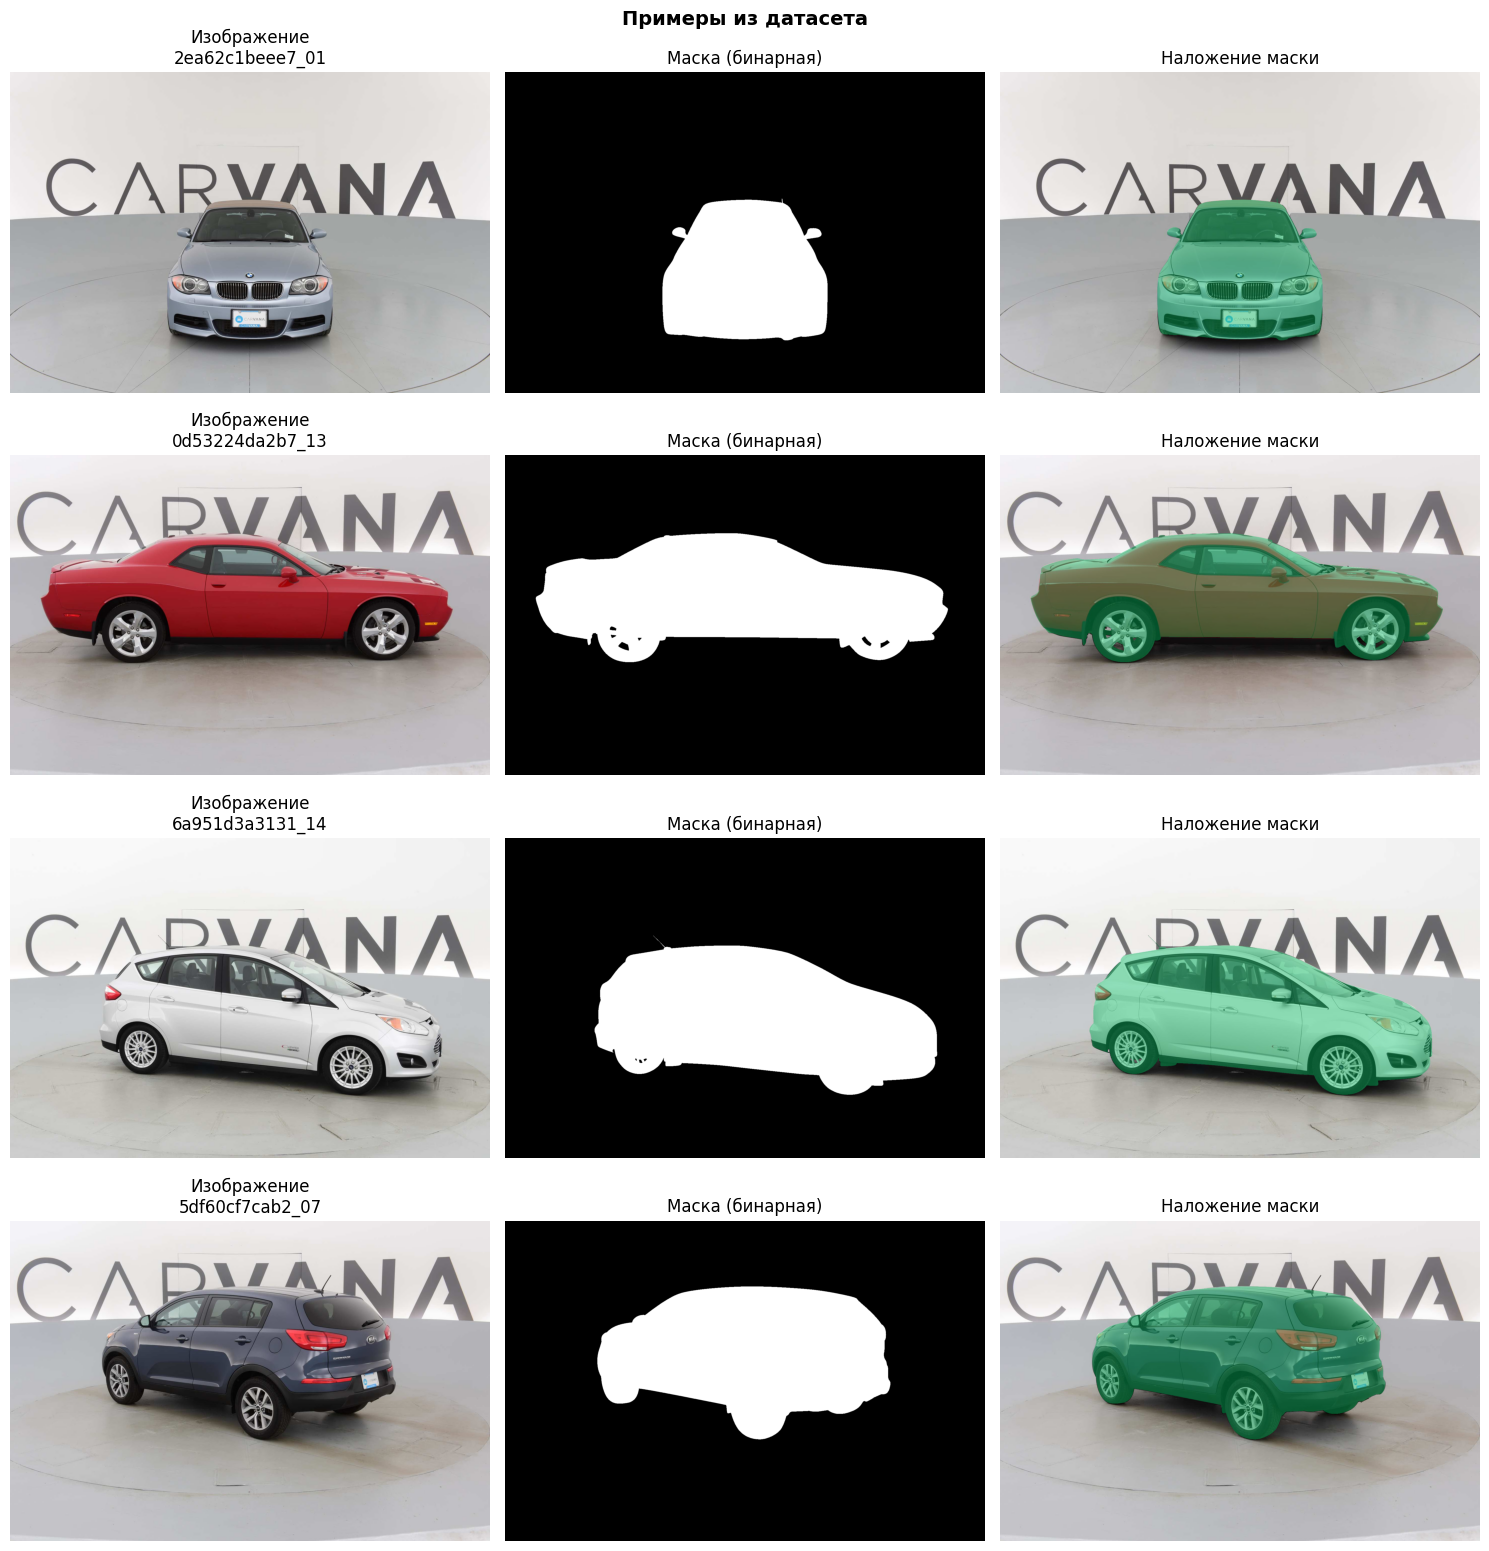

In [ ]:
# Визуализация изображений, масок и наложения
def show_samples (img_paths ,mask_paths ,n =4 ,title ="Примеры из датасета"):
    fig ,axes =plt .subplots (n ,3 ,figsize =(15 ,4 *n ))
    fig .suptitle (title ,fontsize =14 ,fontweight ="bold")

    for i ,(ip ,mp )in enumerate (zip (img_paths [:n ],mask_paths [:n ])):
        img =np .array (Image .open (ip ))
        mask =np .array (Image .open (mp ).convert ("L"))

        mask_bin =(mask >127 ).astype (np .uint8 )

        overlay =img .copy ()
        overlay [mask_bin ==1 ]=(overlay [mask_bin ==1 ]*0.6 +
        np .array ([0 ,200 ,100 ])*0.4 ).astype (np .uint8 )

        axes [i ,0 ].imshow (img )
        axes [i ,0 ].set_title (f"Изображение\n{ip .stem }")
        axes [i ,0 ].axis ("off")

        axes [i ,1 ].imshow (mask_bin ,cmap ="gray")
        axes [i ,1 ].set_title ("Маска (бинарная)")
        axes [i ,1 ].axis ("off")

        axes [i ,2 ].imshow (overlay )
        axes [i ,2 ].set_title ("Наложение маски")
        axes [i ,2 ].axis ("off")

    plt .tight_layout ()
    plt .show ()

idxs =random .sample (range (len (img_files )),min (4 ,len (img_files )))
show_samples ([img_files [i ]for i in idxs ],[mask_files [i ]for i in idxs ])


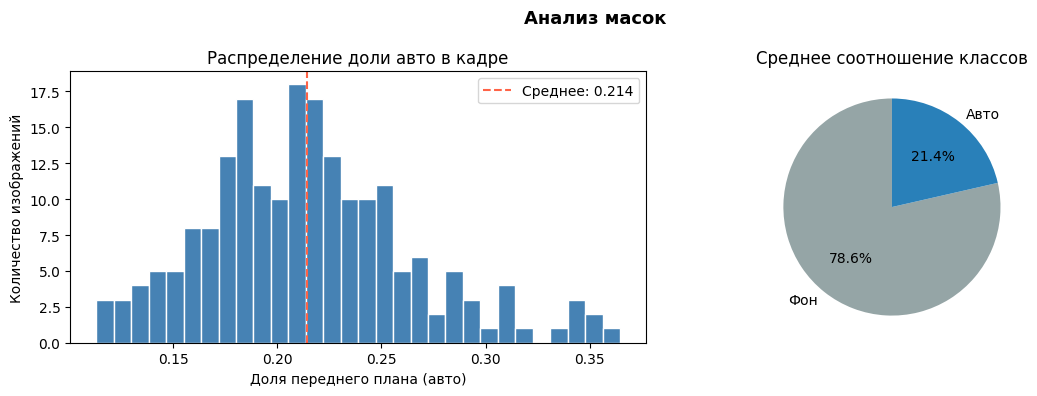

Среднее заполнение маски: 0.214 ± 0.050


In [ ]:
# Анализ распределения классов по маскам
fg_ratios =[]
for mp in random .sample (mask_files ,min (200 ,len (mask_files ))):
    m =np .array (Image .open (mp ).convert ("L"))
    fg_ratios .append ((m >127 ).mean ())

fg_ratios =np .array (fg_ratios )

fig ,axes =plt .subplots (1 ,2 ,figsize =(12 ,4 ))
fig .suptitle ("Анализ масок",fontsize =13 ,fontweight ="bold")

axes [0 ].hist (fg_ratios ,bins =30 ,color ="steelblue",edgecolor ="white")
axes [0 ].set_xlabel ("Доля переднего плана (авто)")
axes [0 ].set_ylabel ("Количество изображений")
axes [0 ].set_title ("Распределение доли авто в кадре")
axes [0 ].axvline (fg_ratios .mean (),color ="tomato",linestyle ="--",
label =f"Среднее: {fg_ratios .mean ():.3f}")
axes [0 ].legend ()

labels =["Фон","Авто"]
sizes =[1 -fg_ratios .mean (),fg_ratios .mean ()]
axes [1 ].pie (sizes ,labels =labels ,autopct ="%1.1f%%",
colors =["#95a5a6","#2980b9"],startangle =90 )
axes [1 ].set_title ("Среднее соотношение классов")

plt .tight_layout ()
plt .show ()
print (f"Среднее заполнение маски: {fg_ratios .mean ():.3f} ± {fg_ratios .std ():.3f}")


## Предобработка и аугментация

In [3]:
# Задание гиперпараметров обучения
IMG_H ,IMG_W =320 ,480
BATCH_SIZE =8
NUM_EPOCHS =20
LR =1e-4
VAL_SPLIT =0.15

print (f"Размер изображений для обучения: {IMG_H }×{IMG_W }")
print (f"Оригинальное разрешение: {sample_img .size [1 ]}×{sample_img .size [0 ]}")
print (f"Коэффициент уменьшения: {sample_img .size [1 ]/IMG_H :.1f}x")


Размер изображений для обучения: 320×480


NameError: name 'sample_img' is not defined

In [ ]:
train_transform =A .Compose ([
A .Resize (IMG_H ,IMG_W ),

A .HorizontalFlip (p =0.5 ),
A .Rotate (limit =10 ,p =0.4 ),

A .ColorJitter (brightness =0.2 ,contrast =0.2 ,saturation =0.1 ,p =0.3 ),
A .GaussNoise (p =0.1 ),

A .Normalize (mean =(0.485 ,0.456 ,0.406 ),
std =(0.229 ,0.224 ,0.225 )),
A .ToTensorV2 (),
])

val_transform =A .Compose ([
A .Resize (IMG_H ,IMG_W ),
A .Normalize (mean =(0.485 ,0.456 ,0.406 ),
std =(0.229 ,0.224 ,0.225 )),
A .ToTensorV2 (),
])

print ("Train:",[t .__class__ .__name__ for t in train_transform .transforms ])


Train: ['Resize', 'HorizontalFlip', 'Rotate', 'ColorJitter', 'GaussNoise', 'Normalize', 'ToTensorV2']


In [ ]:
# Определение класса датасета для обучения
class CarvanaDataset (Dataset ):
    def __init__ (self ,img_paths ,mask_paths ,transform =None ):
        self .img_paths =img_paths
        self .mask_paths =mask_paths
        self .transform =transform

    def __len__ (self ):
        return len (self .img_paths )

    def __getitem__ (self ,idx ):
        img =np .array (Image .open (self .img_paths [idx ]).convert ("RGB"))
        mask =np .array (Image .open (self .mask_paths [idx ]).convert ("L"))

        mask =(mask >127 ).astype (np .float32 )

        if self .transform :
            augmented =self .transform (image =img ,mask =mask )
            img =augmented ["image"]
            mask =augmented ["mask"].unsqueeze (0 )

        return img ,mask

all_pairs =list (zip (img_files ,mask_files ))
random .shuffle (all_pairs )

val_size =int (len (all_pairs )*VAL_SPLIT )
val_pairs =all_pairs [:val_size ]
trn_pairs =all_pairs [val_size :]

train_imgs ,train_masks =zip (*trn_pairs )
val_imgs ,val_masks =zip (*val_pairs )

train_dataset =CarvanaDataset (train_imgs ,train_masks ,transform =train_transform )
val_dataset =CarvanaDataset (val_imgs ,val_masks ,transform =val_transform )

train_loader =DataLoader (train_dataset ,batch_size =BATCH_SIZE ,
shuffle =True ,num_workers =0 ,pin_memory =False )
val_loader =DataLoader (val_dataset ,batch_size =BATCH_SIZE ,
shuffle =False ,num_workers =0 ,pin_memory =False )

print (f"Train: {len (train_dataset )} образцов, {len (train_loader )} батчей")
print (f"Val:   {len (val_dataset )} образцов, {len (val_loader )} батчей")


Train: 4325 образцов, 541 батчей
Val:   763 образцов, 96 батчей


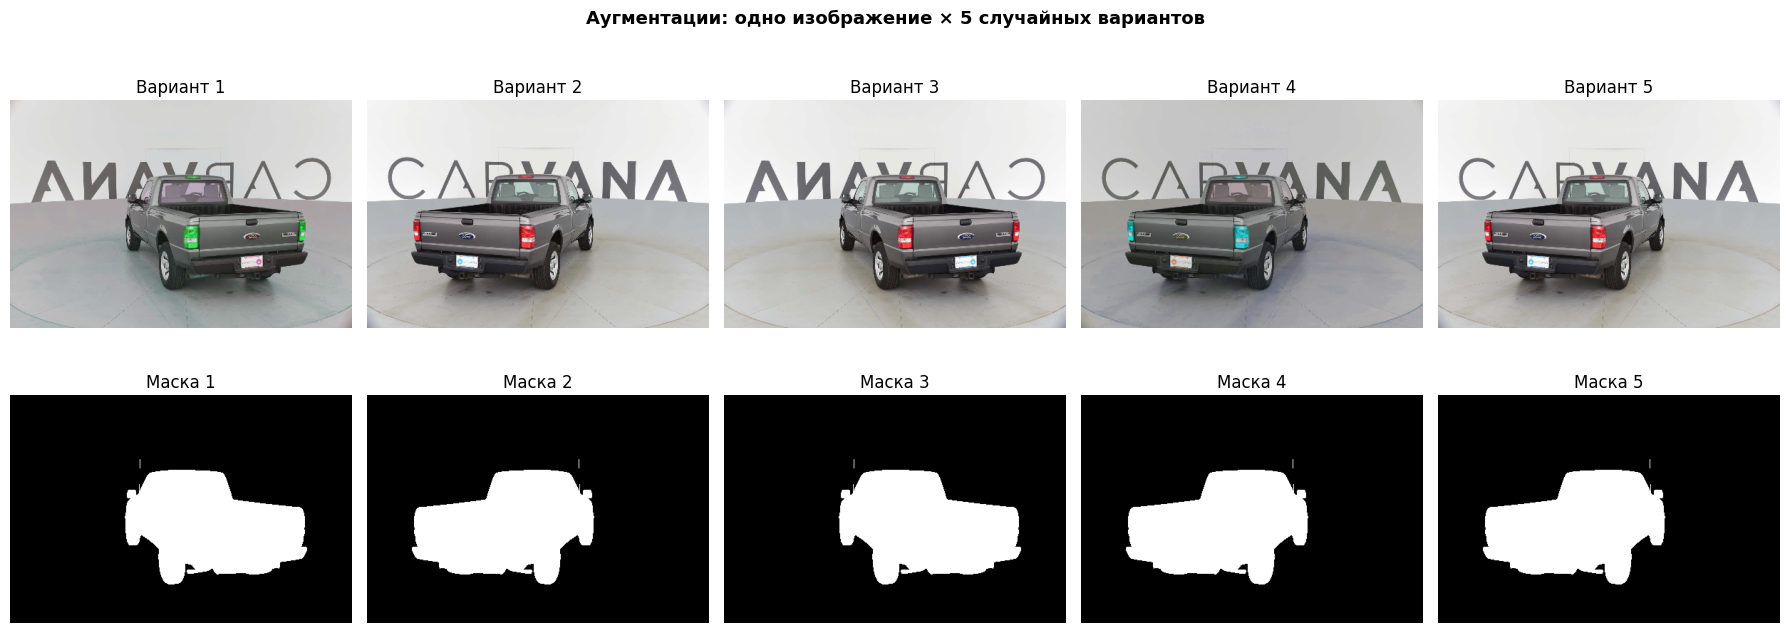

In [ ]:
def denormalize (tensor ):
    mean =torch .tensor ([0.485 ,0.456 ,0.406 ]).view (3 ,1 ,1 )
    std =torch .tensor ([0.229 ,0.224 ,0.225 ]).view (3 ,1 ,1 )
    return (tensor *std +mean ).clamp (0 ,1 )

fig ,axes =plt .subplots (2 ,5 ,figsize =(18 ,7 ))
fig .suptitle ("Аугментации: одно изображение × 5 случайных вариантов",
fontsize =13 ,fontweight ="bold")

src_img =np .array (Image .open (train_imgs [0 ]).convert ("RGB"))
src_mask =(np .array (Image .open (train_masks [0 ]).convert ("L"))>127 ).astype (np .float32 )

for j in range (5 ):
    aug =train_transform (image =src_img ,mask =src_mask )
    img_t =denormalize (aug ["image"]).permute (1 ,2 ,0 ).numpy ()
    mask_t =aug ["mask"].numpy ()

    axes [0 ,j ].imshow (img_t )
    axes [0 ,j ].set_title (f"Вариант {j +1 }")
    axes [0 ,j ].axis ("off")

    axes [1 ,j ].imshow (mask_t ,cmap ="gray")
    axes [1 ,j ].set_title (f"Маска {j +1 }")
    axes [1 ,j ].axis ("off")

plt .tight_layout ()
plt .show ()


## Функции потерь и метрики

In [ ]:
# Определение функций потерь для сегментации
class BCELoss (nn .Module ):
    def __init__ (self ):
        super ().__init__ ()
        self .bce =nn .BCEWithLogitsLoss ()

    def forward (self ,pred ,target ):
        return self .bce (pred ,target )

class DiceLoss (nn .Module ):
    def __init__ (self ,smooth =1.0 ):
        super ().__init__ ()
        self .smooth =smooth

    def forward (self ,pred ,target ):
        pred =torch .sigmoid (pred )
        pred =pred .view (-1 )
        target =target .view (-1 )

        intersection =(pred *target ).sum ()
        dice =(2. *intersection +self .smooth )/(pred .sum ()+target .sum ()+self .smooth )
        return 1 -dice

class BCEDiceLoss (nn .Module ):
    def __init__ (self ,bce_weight =0.5 ):
        super ().__init__ ()
        self .bce_w =bce_weight
        self .bce =BCELoss ()
        self .dice =DiceLoss ()

    def forward (self ,pred ,target ):
        return self .bce_w *self .bce (pred ,target )+(1 -self .bce_w )*self .dice (pred ,target )

@torch .no_grad ()
def dice_score (pred ,target ,threshold =0.5 ,smooth =1.0 ):
    pred =(torch .sigmoid (pred )>threshold ).float ()
    pred =pred .view (-1 )
    target =target .view (-1 )
    intersection =(pred *target ).sum ()
    return ((2. *intersection +smooth )/
    (pred .sum ()+target .sum ()+smooth )).item ()

@torch .no_grad ()
def iou_score (pred ,target ,threshold =0.5 ,smooth =1.0 ):
    pred =(torch .sigmoid (pred )>threshold ).float ()
    pred =pred .view (-1 )
    target =target .view (-1 )
    intersection =(pred *target ).sum ()
    union =pred .sum ()+target .sum ()-intersection
    return ((intersection +smooth )/(union +smooth )).item ()

print ("  Потери: BCELoss, DiceLoss, BCEDiceLoss")
print ("  Метрики: dice_score, iou_score")


  Потери: BCELoss, DiceLoss, BCEDiceLoss
  Метрики: dice_score, iou_score


## Библиотечная модель U-Net (segmentation_models_pytorch)

In [6]:
lib_model =smp .Unet (
encoder_name ="efficientnet-b0",
encoder_weights ="imagenet",
in_channels =3 ,
classes =1 ,
activation =None ,
).to (DEVICE )

total_params =sum (p .numel ()for p in lib_model .parameters ())
train_params =sum (p .numel ()for p in lib_model .parameters ()if p .requires_grad )
print (f"Всего параметров:    {total_params :,}")
print (f"Обучаемых параметров: {train_params :,}")


Всего параметров:    6,251,469
Обучаемых параметров: 6,251,469


In [8]:
# Функции цикла обучения и оценки модели
def train_epoch (model ,loader ,optimizer ,criterion ):
    model .train ()
    total_loss =0
    for imgs ,masks in tqdm (loader ,desc ="Train",leave =False ):
        imgs ,masks =imgs .to (DEVICE ),masks .to (DEVICE )
        optimizer .zero_grad ()
        preds =model (imgs )
        loss =criterion (preds ,masks )
        loss .backward ()
        optimizer .step ()
        total_loss +=loss .item ()
    return total_loss /len (loader )

@torch .no_grad ()
def eval_epoch (model ,loader ,criterion ):
    model .eval ()
    total_loss ,total_dice ,total_iou =0 ,0 ,0
    for imgs ,masks in tqdm (loader ,desc ="Val",leave =False ):
        imgs ,masks =imgs .to (DEVICE ),masks .to (DEVICE )
        preds =model (imgs )
        total_loss +=criterion (preds ,masks ).item ()
        total_dice +=dice_score (preds ,masks )
        total_iou +=iou_score (preds ,masks )
    n =len (loader )
    return total_loss /n ,total_dice /n ,total_iou /n

def run_experiment (model ,loss_name ,criterion ,n_epochs =NUM_EPOCHS ):
    optimizer =optim .AdamW (model .parameters (),lr =LR ,weight_decay =1e-4 )
    scheduler =optim .lr_scheduler .CosineAnnealingLR (optimizer ,T_max =n_epochs )

    history ={"train_loss":[],"val_loss":[],"val_dice":[],"val_iou":[]}
    best_dice ,best_epoch =0 ,0

    for epoch in range (1 ,n_epochs +1 ):
        tr_loss =train_epoch (model ,train_loader ,optimizer ,criterion )
        vl_loss ,vl_dice ,vl_iou =eval_epoch (model ,val_loader ,criterion )
        scheduler .step ()

        history ["train_loss"].append (tr_loss )
        history ["val_loss"].append (vl_loss )
        history ["val_dice"].append (vl_dice )
        history ["val_iou"].append (vl_iou )

        if vl_dice >best_dice :
            best_dice ,best_epoch =vl_dice ,epoch
            torch .save (model .state_dict (),f"best_{loss_name }.pth")

        print (f"[{loss_name }] Epoch {epoch :02d}/{n_epochs } | "
        f"Train Loss: {tr_loss :.4f} | "
        f"Val Loss: {vl_loss :.4f} | "
        f"Dice: {vl_dice :.4f} | "
        f"IoU: {vl_iou :.4f}")

    print (f"\n[{loss_name }] Лучший Dice: {best_dice :.4f} на эпохе {best_epoch }")
    return history

def save_histories_json (histories ,path ="histories_segmentation.json"):
    import json
    histories ={k :v for k ,v in histories .items () if v is not None }
    with open (path ,"w",encoding ="utf-8") as f :
        json .dump (histories ,f ,ensure_ascii =False ,indent =2 )
    print (f"Истории сохранены: {path }")

def load_histories_json (path ="histories_segmentation.json"):
    import json
    if not Path (path ).exists ():
        return {}
    with open (path ,"r",encoding ="utf-8") as f :
        data =json .load (f )
    print (f"Истории загружены: {path }")
    return data


NameError: name 'NUM_EPOCHS' is not defined

In [26]:
# Обучение модели с BCE loss
print ("ЭКСПЕРИМЕНТ 1: BCE Loss")
print ("-"*60 )

model_bce =smp .Unet (
encoder_name ="efficientnet-b0",encoder_weights ="imagenet",
in_channels =3 ,classes =1 ,activation =None
).to (DEVICE )

history_bce =run_experiment (model_bce ,"BCE",BCELoss ())
save_histories_json ({"BCE":history_bce })


ЭКСПЕРИМЕНТ 1: BCE Loss
------------------------------------------------------------


[BCE] Epoch 01/20 | Train Loss: 0.1531 | Val Loss: 0.0441 | Dice: 0.9875 | IoU: 0.9752


[BCE] Epoch 02/20 | Train Loss: 0.0318 | Val Loss: 0.0201 | Dice: 0.9904 | IoU: 0.9811


[BCE] Epoch 03/20 | Train Loss: 0.0190 | Val Loss: 0.0136 | Dice: 0.9916 | IoU: 0.9834


[BCE] Epoch 04/20 | Train Loss: 0.0142 | Val Loss: 0.0107 | Dice: 0.9925 | IoU: 0.9851


...

[BCE] Epoch 16/20 | Train Loss: 0.0073 | Val Loss: 0.0059 | Dice: 0.9944 | IoU: 0.9888


[BCE] Epoch 17/20 | Train Loss: 0.0071 | Val Loss: 0.0058 | Dice: 0.9944 | IoU: 0.9889


[BCE] Epoch 18/20 | Train Loss: 0.0071 | Val Loss: 0.0058 | Dice: 0.9945 | IoU: 0.9890


[BCE] Epoch 19/20 | Train Loss: 0.0071 | Val Loss: 0.0058 | Dice: 0.9945 | IoU: 0.9890


[BCE] Epoch 20/20 | Train Loss: 0.0070 | Val Loss: 0.0058 | Dice: 0.9945 | IoU: 0.9890

[BCE] Лучший Dice: 0.9945 на эпохе 20


In [27]:
# Обучение модели с Dice loss
print ("ЭКСПЕРИМЕНТ 2: Dice Loss")
print ("-"*60 )

model_dice =smp .Unet (
encoder_name ="efficientnet-b0",encoder_weights ="imagenet",
in_channels =3 ,classes =1 ,activation =None
).to (DEVICE )

history_dice =run_experiment (model_dice ,"Dice",DiceLoss ())
save_histories_json ({
    "BCE":globals ().get ("history_bce"),
    "Dice":history_dice ,
})


ЭКСПЕРИМЕНТ 2: Dice Loss
------------------------------------------------------------


[Dice] Epoch 01/20 | Train Loss: 0.1917 | Val Loss: 0.0555 | Dice: 0.9869 | IoU: 0.9741


[Dice] Epoch 02/20 | Train Loss: 0.0362 | Val Loss: 0.0219 | Dice: 0.9905 | IoU: 0.9812


[Dice] Epoch 03/20 | Train Loss: 0.0197 | Val Loss: 0.0149 | Dice: 0.9911 | IoU: 0.9824


[Dice] Epoch 04/20 | Train Loss: 0.0147 | Val Loss: 0.0115 | Dice: 0.9919 | IoU: 0.9840


...

[Dice] Epoch 16/20 | Train Loss: 0.0072 | Val Loss: 0.0059 | Dice: 0.9943 | IoU: 0.9887


[Dice] Epoch 17/20 | Train Loss: 0.0072 | Val Loss: 0.0058 | Dice: 0.9944 | IoU: 0.9889


[Dice] Epoch 18/20 | Train Loss: 0.0071 | Val Loss: 0.0058 | Dice: 0.9945 | IoU: 0.9890


[Dice] Epoch 19/20 | Train Loss: 0.0071 | Val Loss: 0.0058 | Dice: 0.9945 | IoU: 0.9890


[Dice] Epoch 20/20 | Train Loss: 0.0071 | Val Loss: 0.0058 | Dice: 0.9945 | IoU: 0.9890

[Dice] Лучший Dice: 0.9945 на эпохе 19


In [28]:
# Обучение модели с комбинированной функцией потерь
print ("ЭКСПЕРИМЕНТ 3: BCE + Dice Loss")
print ("-"*60 )

model_combo =smp .Unet (
encoder_name ="efficientnet-b0",encoder_weights ="imagenet",
in_channels =3 ,classes =1 ,activation =None
).to (DEVICE )

history_combo =run_experiment (model_combo ,"BCE+Dice",BCEDiceLoss ())
save_histories_json ({
    "BCE":globals ().get ("history_bce"),
    "Dice":globals ().get ("history_dice"),
    "BCE+Dice":history_combo ,
})


ЭКСПЕРИМЕНТ 3: BCE + Dice Loss
------------------------------------------------------------


[BCE+Dice] Epoch 01/20 | Train Loss: 0.1615 | Val Loss: 0.0441 | Dice: 0.9887 | IoU: 0.9777


[BCE+Dice] Epoch 02/20 | Train Loss: 0.0324 | Val Loss: 0.0198 | Dice: 0.9906 | IoU: 0.9814


[BCE+Dice] Epoch 03/20 | Train Loss: 0.0194 | Val Loss: 0.0140 | Dice: 0.9918 | IoU: 0.9838


[BCE+Dice] Epoch 04/20 | Train Loss: 0.0154 | Val Loss: 0.0115 | Dice: 0.9923 | IoU: 0.9846


...

[BCE+Dice] Epoch 16/20 | Train Loss: 0.0082 | Val Loss: 0.0066 | Dice: 0.9945 | IoU: 0.9890


[BCE+Dice] Epoch 17/20 | Train Loss: 0.0081 | Val Loss: 0.0066 | Dice: 0.9945 | IoU: 0.9891


[BCE+Dice] Epoch 18/20 | Train Loss: 0.0080 | Val Loss: 0.0065 | Dice: 0.9945 | IoU: 0.9891


[BCE+Dice] Epoch 19/20 | Train Loss: 0.0081 | Val Loss: 0.0065 | Dice: 0.9945 | IoU: 0.9891


[BCE+Dice] Epoch 20/20 | Train Loss: 0.0080 | Val Loss: 0.0065 | Dice: 0.9946 | IoU: 0.9892

[BCE+Dice] Лучший Dice: 0.9946 на эпохе 20


## Сравнение результатов и визуализация

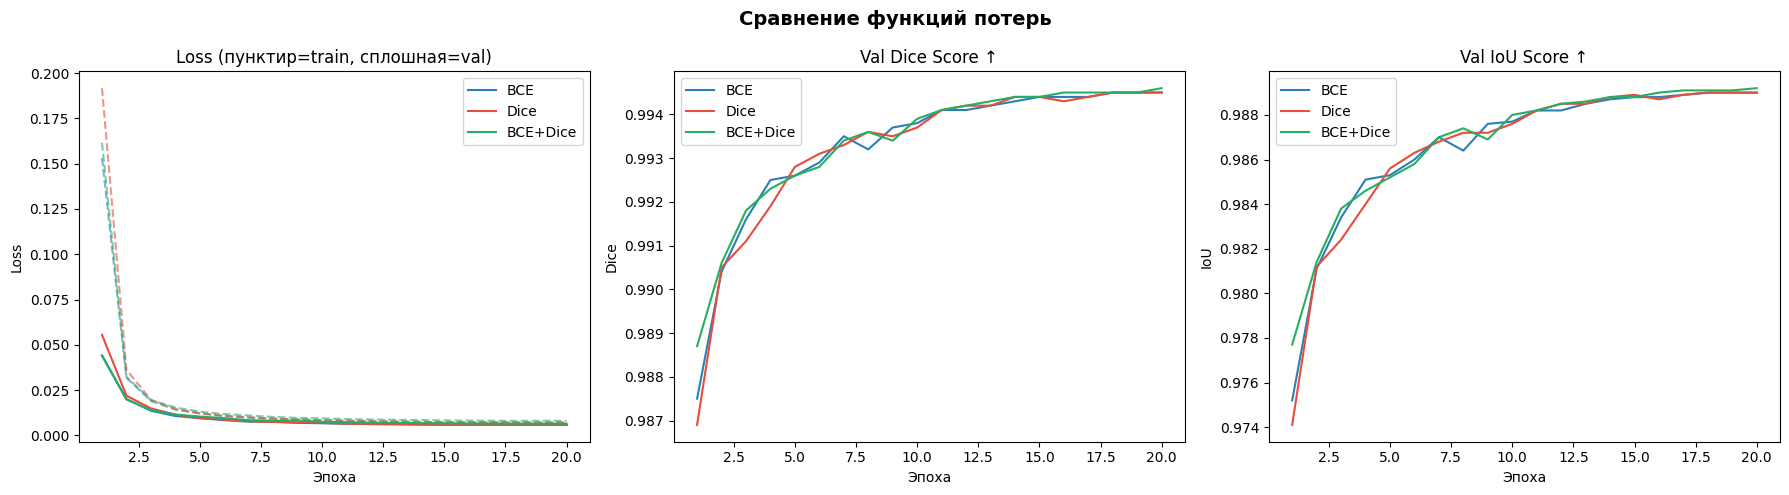

In [3]:
# Сравнение динамики обучения разных моделей
def plot_histories (histories :dict ):
    colors =["#2980b9","#e74c3c","#27ae60"]
    fig ,axes =plt .subplots (1 ,3 ,figsize =(18 ,5 ))
    fig .suptitle ("Сравнение функций потерь",fontsize =14 ,fontweight ="bold")

    for (name ,h ),c in zip (histories .items (),colors ):
        epochs =range (1 ,len (h ["val_dice"])+1 )
        axes [0 ].plot (epochs ,h ["train_loss"],linestyle ="--",color =c ,alpha =0.6 )
        axes [0 ].plot (epochs ,h ["val_loss"],linestyle ="-",color =c ,label =name )
        axes [1 ].plot (epochs ,h ["val_dice"],linestyle ="-",color =c ,label =name )
        axes [2 ].plot (epochs ,h ["val_iou"],linestyle ="-",color =c ,label =name )

    axes [0 ].set_title ("Loss (пунктир=train, сплошная=val)")
    axes [0 ].set_xlabel ("Эпоха");axes [0 ].set_ylabel ("Loss")
    axes [0 ].legend ()

    axes [1 ].set_title ("Val Dice Score ↑")
    axes [1 ].set_xlabel ("Эпоха");axes [1 ].set_ylabel ("Dice")
    axes [1 ].legend ()

    axes [2 ].set_title ("Val IoU Score ↑")
    axes [2 ].set_xlabel ("Эпоха");axes [2 ].set_ylabel ("IoU")
    axes [2 ].legend ()

    plt .tight_layout ()
    plt .show ()

if "load_histories_json" not in globals ():
    def load_histories_json (path ="histories_segmentation.json"):
        import json
        if not Path (path ).exists ():
            return {}
        with open (path ,"r",encoding ="utf-8") as f :
            return json .load (f )

if "save_histories_json" not in globals ():
    def save_histories_json (histories ,path ="histories_segmentation.json"):
        import json
        histories ={k :v for k ,v in histories .items () if v is not None }
        with open (path ,"w",encoding ="utf-8") as f :
            json .dump (histories ,f ,ensure_ascii =False ,indent =2 )

history_candidates ={
"BCE":globals ().get ("history_bce"),
"Dice":globals ().get ("history_dice"),
"BCE+Dice":globals ().get ("history_combo"),
}
histories ={k :v for k ,v in history_candidates .items () if v is not None }

if len (histories )==0 :
    histories =load_histories_json ()

if len (histories )==0 :
    import json
    import re
    from pathlib import Path

    nb_path =Path ("task_3_7_semantic_segmentation.ipynb")
    if nb_path .exists ():
        raw =json .loads (nb_path .read_text (encoding ="utf-8"))
        pattern =re .compile (
            r"\[(BCE\+Dice|BCE|Dice)\] Epoch \d+/\d+ \| Train Loss: ([0-9.]+) \| Val Loss: ([0-9.]+) \| Dice: ([0-9.]+) \| IoU: ([0-9.]+)"
        )
        parsed ={
            "BCE":{"train_loss":[],"val_loss":[],"val_dice":[],"val_iou":[]},
            "Dice":{"train_loss":[],"val_loss":[],"val_dice":[],"val_iou":[]},
            "BCE+Dice":{"train_loss":[],"val_loss":[],"val_dice":[],"val_iou":[]},
        }

        for cell in raw .get ("cells",[]):
            for out in cell .get ("outputs",[]):
                for line in out .get ("text",[]):
                    m =pattern .search (line )
                    if m is None :
                        continue
                    name ,tr ,vl ,vd ,vi =m .groups ()
                    parsed [name ]["train_loss"].append (float (tr ))
                    parsed [name ]["val_loss"].append (float (vl ))
                    parsed [name ]["val_dice"].append (float (vd ))
                    parsed [name ]["val_iou"].append (float (vi ))

        histories ={k :v for k ,v in parsed .items () if len (v ["val_dice"])>0 }

if len (histories )==0 :
    raise RuntimeError (
    "Не найдены history_* в памяти и не удалось восстановить из вывода ноутбука. Выполните ячейки обучения BCE/Dice/BCE+Dice."
    )

if "history_bce" not in globals () and "BCE" in histories :
    history_bce =histories ["BCE"]
if "history_dice" not in globals () and "Dice" in histories :
    history_dice =histories ["Dice"]
if "history_combo" not in globals () and "BCE+Dice" in histories :
    history_combo =histories ["BCE+Dice"]

save_histories_json (histories )
plot_histories (histories )


In [4]:
print (f"{'Модель':<15} | {'Лучший Dice':>12} | {'Лучший IoU':>11} | {'Мин. Val Loss':>13}")
print ("-"*60 )
for name ,h in histories .items ():
    best_dice =max (h ["val_dice"])
    best_iou =max (h ["val_iou"])
    min_loss =min (h ["val_loss"])
    print (f"{name :<15} | {best_dice :>12.4f} | {best_iou :>11.4f} | {min_loss :>13.4f}")


Модель          |  Лучший Dice |  Лучший IoU | Мин. Val Loss
------------------------------------------------------------
BCE             |       0.9945 |      0.9890 |        0.0058
Dice            |       0.9945 |      0.9890 |        0.0058
BCE+Dice        |       0.9946 |      0.9892 |        0.0065


In [5]:
# Визуализация изображений, масок и наложения
def visualize_predictions (model ,dataset ,n =4 ,title ="Предсказания модели"):
    model .eval ()
    indices =random .sample (range (len (dataset )),n )

    fig ,axes =plt .subplots (n ,4 ,figsize =(16 ,4 *n ))
    fig .suptitle (title ,fontsize =13 ,fontweight ="bold")
    col_titles =["Изображение","GT Маска","Предсказание","Наложение"]
    for ax ,ct in zip (axes [0 ],col_titles ):
        ax .set_title (ct ,fontsize =11 )

    with torch .no_grad ():
        for row ,idx in enumerate (indices ):
            img_t ,mask_t =dataset [idx ]
            pred =torch .sigmoid (model (img_t .unsqueeze (0 ).to (DEVICE )))
            pred =(pred >0.5 ).float ().cpu ().squeeze ()

            img_vis =denormalize (img_t ).permute (1 ,2 ,0 ).numpy ()
            mask_vis =mask_t .squeeze ().numpy ()
            pred_vis =pred .numpy ()

            overlay =(img_vis *255 ).astype (np .uint8 ).copy ()
            overlay [pred_vis ==1 ]=(
            overlay [pred_vis ==1 ]*0.55 +
            np .array ([30 ,180 ,100 ])*0.45
            ).astype (np .uint8 )

            axes [row ,0 ].imshow (img_vis )
            axes [row ,1 ].imshow (mask_vis ,cmap ="gray")
            axes [row ,2 ].imshow (pred_vis ,cmap ="gray")
            axes [row ,3 ].imshow (overlay )

            dice =dice_score (model (img_t .unsqueeze (0 ).to (DEVICE )),
            mask_t .unsqueeze (0 ).to (DEVICE ))
            iou =iou_score (model (img_t .unsqueeze (0 ).to (DEVICE )),
            mask_t .unsqueeze (0 ).to (DEVICE ))
            axes [row ,0 ].set_ylabel (f"Dice={dice :.3f}\nIoU={iou :.3f}",fontsize =9 )

            for ax in axes [row ]:
                ax .axis ("off")

    plt .tight_layout ()
    plt .show ()

if "smp" not in globals ():
    import segmentation_models_pytorch as smp
if "Path" not in globals ():
    from pathlib import Path

if "histories" in globals () and len (histories )>0 :
    best_model_name =max (histories ,key =lambda k :max (histories [k ]["val_dice"]))
else :
    checkpoint_map ={
        "BCE":"best_BCE.pth",
        "Dice":"best_Dice.pth",
        "BCE+Dice":"best_BCE+Dice.pth",
    }
    available =[name for name ,p in checkpoint_map .items () if Path (p ).exists ()]
    if len (available )==0 :
        raise RuntimeError ("Не найдены best_BCE.pth / best_Dice.pth / best_BCE+Dice.pth")
    if "val_loader" not in globals ():
        raise RuntimeError ("histories не найдены, а val_loader отсутствует для выбора лучшей модели")

    @torch .no_grad ()
    def eval_ckpt_dice (ckpt_path ):
        m =smp .Unet (
            encoder_name ="efficientnet-b0",encoder_weights ="imagenet",
            in_channels =3 ,classes =1 ,activation =None
        ).to (DEVICE )
        m .load_state_dict (torch .load (ckpt_path ,map_location =DEVICE ))
        m .eval ()
        total ,n =0.0 ,0
        for imgs ,masks in val_loader :
            imgs ,masks =imgs .to (DEVICE ),masks .to (DEVICE )
            total +=dice_score (m (imgs ),masks )
            n +=1
        return total /max (n ,1 )

    ckpt_scores ={name :eval_ckpt_dice (checkpoint_map [name ]) for name in available }
    best_model_name =max (ckpt_scores ,key =ckpt_scores .get )
    print (f"Выбор лучшей по чекпоинтам на val: {ckpt_scores }")

best_model =smp .Unet (
    encoder_name ="efficientnet-b0",encoder_weights ="imagenet",
    in_channels =3 ,classes =1 ,activation =None
).to (DEVICE )
best_model .load_state_dict (torch .load (f"best_{best_model_name }.pth",map_location =DEVICE ))

print (f"Лучшая модель: {best_model_name }")
visualize_predictions (best_model ,val_dataset ,
title =f"Лучшая модель ({best_model_name }) — примеры на val")


Лучшая модель: BCE+Dice


NameError: name 'val_dataset' is not defined

---
## Собственная реализация U-Net

### Идеи и решения:
- **Высокое разрешение**: используем архитектуру с глубокими skip-connections и добавляем **ASPP** (Atrous Spatial Pyramid Pooling) для многомасштабного контекста
- **Однообразный фон**: применяем **Focal Loss** компонент, чтобы модель концентрировалась на трудных пикселях границ
- **Качество границ**: добавляем **Squeeze-and-Excitation** блоки для адаптивного взвешивания каналов
- **Предобученный энкодер**: опционально используем ImageNet-веса

In [18]:
# Определение собственной архитектуры U-Net
class DoubleConv (nn .Module ):
    def __init__ (self ,in_ch ,out_ch ,mid_ch =None ):
        super ().__init__ ()
        mid_ch =mid_ch or out_ch
        self .net =nn .Sequential (
        nn .Conv2d (in_ch ,mid_ch ,3 ,padding =1 ,bias =False ),
        nn .BatchNorm2d (mid_ch ),
        nn .ReLU (inplace =True ),
        nn .Conv2d (mid_ch ,out_ch ,3 ,padding =1 ,bias =False ),
        nn .BatchNorm2d (out_ch ),
        nn .ReLU (inplace =True ),
        )

    def forward (self ,x ):
        return self .net (x )

class SEBlock (nn .Module ):
    def __init__ (self ,channels ,ratio =16 ):
        super ().__init__ ()
        self .se =nn .Sequential (
        nn .AdaptiveAvgPool2d (1 ),
        nn .Flatten (),
        nn .Linear (channels ,channels //ratio ),
        nn .ReLU (inplace =True ),
        nn .Linear (channels //ratio ,channels ),
        nn .Sigmoid (),
        )

    def forward (self ,x ):
        scale =self .se (x ).view (x .size (0 ),x .size (1 ),1 ,1 )
        return x *scale

class EncoderBlock (nn .Module ):
    def __init__ (self ,in_ch ,out_ch ):
        super ().__init__ ()
        self .conv =DoubleConv (in_ch ,out_ch )
        self .se =SEBlock (out_ch )
        self .pool =nn .MaxPool2d (2 )

    def forward (self ,x ):
        skip =self .se (self .conv (x ))
        return self .pool (skip ),skip

class DecoderBlock (nn .Module ):
    def __init__ (self ,in_ch ,skip_ch ,out_ch ):
        super ().__init__ ()
        self .up =nn .ConvTranspose2d (in_ch ,in_ch //2 ,2 ,stride =2 )
        self .conv =DoubleConv (in_ch //2 +skip_ch ,out_ch )
        self .se =SEBlock (out_ch )

    def forward (self ,x ,skip ):
        x =self .up (x )

        if x .shape !=skip .shape :
            x =TF .resize (x ,skip .shape [-2 :])
        x =torch .cat ([skip ,x ],dim =1 )
        return self .se (self .conv (x ))

class ASPP (nn .Module ):
    def __init__ (self ,in_ch ,out_ch ,rates =(1 ,6 ,12 ,18 )):
        super ().__init__ ()
        self .branches =nn .ModuleList ([
        nn .Sequential (
        nn .Conv2d (in_ch ,out_ch ,3 ,padding =r ,dilation =r ,bias =False ),
        nn .BatchNorm2d (out_ch ),
        nn .ReLU (inplace =True )
        )for r in rates
        ])

        self .global_pool =nn .Sequential (
        nn .AdaptiveAvgPool2d (1 ),
        nn .Conv2d (in_ch ,out_ch ,1 ,bias =False ),
        nn .BatchNorm2d (out_ch ),
        nn .ReLU (inplace =True ),
        )
        self .project =nn .Sequential (
        nn .Conv2d (out_ch *(len (rates )+1 ),out_ch ,1 ,bias =False ),
        nn .BatchNorm2d (out_ch ),
        nn .ReLU (inplace =True ),
        nn .Dropout (0.1 ),
        )

    def forward (self ,x ):
        H ,W =x .shape [-2 :]
        parts =[b (x )for b in self .branches ]
        gp =self .global_pool (x )
        gp =nn .functional .interpolate (gp ,(H ,W ),mode ="bilinear",align_corners =False )
        parts .append (gp )
        return self .project (torch .cat (parts ,dim =1 ))


In [19]:
# Определение собственной архитектуры U-Net
class CustomUNet (nn .Module ):
    def __init__ (self ,in_ch =3 ,out_ch =1 ,features =(64 ,128 ,256 ,512 )):
        super ().__init__ ()

        self .encoders =nn .ModuleList ()
        prev_ch =in_ch
        for f in features :
            self .encoders .append (EncoderBlock (prev_ch ,f ))
            prev_ch =f

        bottleneck_ch =features [-1 ]*2
        self .bottleneck =nn .Sequential (
        DoubleConv (prev_ch ,bottleneck_ch ),
        ASPP (bottleneck_ch ,bottleneck_ch ),
        )

        self .decoders =nn .ModuleList ()
        dec_in =bottleneck_ch
        for f in reversed (features ):
            self .decoders .append (DecoderBlock (dec_in ,f ,f ))
            dec_in =f

        self .head =nn .Conv2d (features [0 ],out_ch ,1 )

        self .aux_head =nn .Conv2d (features [1 ],out_ch ,1 )

        self ._init_weights ()

    def _init_weights (self ):
        for m in self .modules ():
            if isinstance (m ,nn .Conv2d ):
                nn .init .kaiming_normal_ (m .weight ,mode ="fan_out",nonlinearity ="relu")
            elif isinstance (m ,nn .BatchNorm2d ):
                nn .init .ones_ (m .weight )
                nn .init .zeros_ (m .bias )

    def forward (self ,x ):
        skips =[]
        for enc in self .encoders :
            x ,skip =enc (x )
            skips .append (skip )

        x =self .bottleneck (x )

        aux =None
        for i ,dec in enumerate (self .decoders ):
            x =dec (x ,skips [-(i +1 )])

            if i ==len (self .decoders )-2 :
                aux =self .aux_head (x )

        if self .training and aux is not None :
            return self .head (x ),aux
        return self .head (x )

custom_model =CustomUNet ().to (DEVICE )
dummy =torch .randn (2 ,3 ,IMG_H ,IMG_W ).to (DEVICE )
custom_model .train ()
out_main ,out_aux =custom_model (dummy )
print (f"CustomUNet:")
print (f"  Вход:        {dummy .shape }")
print (f"  Выход main:  {out_main .shape }")
print (f"  Выход aux:   {out_aux .shape }")
total =sum (p .numel ()for p in custom_model .parameters ())
print (f"  Параметров:  {total :,}")


CustomUNet:
  Вход:        torch.Size([2, 3, 320, 480])
  Выход main:  torch.Size([2, 1, 320, 480])
  Выход aux:   torch.Size([2, 1, 160, 240])
  Параметров:  75,179,322


In [20]:
class FocalDiceLoss (nn .Module ):
    def __init__ (self ,gamma =2.0 ,alpha =0.25 ,dice_w =0.5 ):
        super ().__init__ ()
        self .gamma =gamma
        self .alpha =alpha
        self .dice_w =dice_w
        self .dice =DiceLoss ()

    def focal (self ,pred ,target ):
        bce =nn .functional .binary_cross_entropy_with_logits (pred ,target ,reduction ="none")
        p_t =torch .exp (-bce )

        a_t =self .alpha *target +(1 -self .alpha )*(1 -target )
        return (a_t *(1 -p_t )**self .gamma *bce ).mean ()

    def forward (self ,pred ,target ):
        return (1 -self .dice_w )*self .focal (pred ,target )+self .dice_w *self .dice (pred ,target )

def train_custom_epoch (model ,loader ,optimizer ,criterion ,aux_weight =0.4 ):
    model .train ()
    total_loss =0
    for imgs ,masks in tqdm (loader ,desc ="Train Custom",leave =False ):
        imgs ,masks =imgs .to (DEVICE ),masks .to (DEVICE )
        optimizer .zero_grad ()

        main_out ,aux_out =model (imgs )

        main_loss =criterion (main_out ,masks )

        aux_masks =nn .functional .interpolate (masks ,aux_out .shape [-2 :],
        mode ="nearest")
        aux_loss =criterion (aux_out ,aux_masks )

        loss =main_loss +aux_weight *aux_loss
        loss .backward ()
        nn .utils .clip_grad_norm_ (model .parameters (),1.0 )
        optimizer .step ()
        total_loss +=loss .item ()

    return total_loss /len (loader )


In [21]:
# Обучение и валидация собственной U-Net
custom_model =CustomUNet (features =(64 ,128 ,256 ,512 )).to (DEVICE )
criterion_custom =FocalDiceLoss (gamma =2.0 ,dice_w =0.6 )
optimizer_custom =optim .AdamW (custom_model .parameters (),lr =LR ,weight_decay =1e-4 )
scheduler_custom =optim .lr_scheduler .OneCycleLR (
optimizer_custom ,max_lr =LR *5 ,
epochs =NUM_EPOCHS ,steps_per_epoch =len (train_loader )
)

custom_history ={"train_loss":[],"val_loss":[],"val_dice":[],"val_iou":[]}
best_custom_dice =0

print ("ЭКСПЕРИМЕНТ 4: Custom U-Net + Focal Dice Loss")
print ("-"*60 )

for epoch in range (1 ,NUM_EPOCHS +1 ):
    tr_loss =train_custom_epoch (custom_model ,train_loader ,
    optimizer_custom ,criterion_custom )

    custom_model .eval ()
    vl_loss ,vl_dice ,vl_iou =0 ,0 ,0
    with torch .no_grad ():
        for imgs ,masks in tqdm (val_loader ,desc ="Val Custom",leave =False ):
            imgs ,masks =imgs .to (DEVICE ),masks .to (DEVICE )
            preds =custom_model (imgs )
            vl_loss +=criterion_custom (preds ,masks ).item ()
            vl_dice +=dice_score (preds ,masks )
            vl_iou +=iou_score (preds ,masks )

    n =len (val_loader )
    vl_loss /=n ;vl_dice /=n ;vl_iou /=n

    custom_history ["train_loss"].append (tr_loss )
    custom_history ["val_loss"].append (vl_loss )
    custom_history ["val_dice"].append (vl_dice )
    custom_history ["val_iou"].append (vl_iou )

    if vl_dice >best_custom_dice :
        best_custom_dice =vl_dice
        torch .save (custom_model .state_dict (),"best_custom_unet.pth")

    print (f"[Custom UNet] Epoch {epoch :02d}/{NUM_EPOCHS } | "
    f"Train Loss: {tr_loss :.4f} | "
    f"Val Loss: {vl_loss :.4f} | "
    f"Dice: {vl_dice :.4f} | "
    f"IoU: {vl_iou :.4f}")

print (f"\nЛучший Dice CustomUNet: {best_custom_dice :.4f}")


ЭКСПЕРИМЕНТ 4: Custom U-Net + Focal Dice Loss
------------------------------------------------------------


[Custom UNet] Epoch 01/20 | Train Loss: 0.1587 | Val Loss: 0.0198 | Dice: 0.9782 | IoU: 0.9574


[Custom UNet] Epoch 02/20 | Train Loss: 0.0308 | Val Loss: 0.0138 | Dice: 0.9849 | IoU: 0.9702


KeyboardInterrupt: 

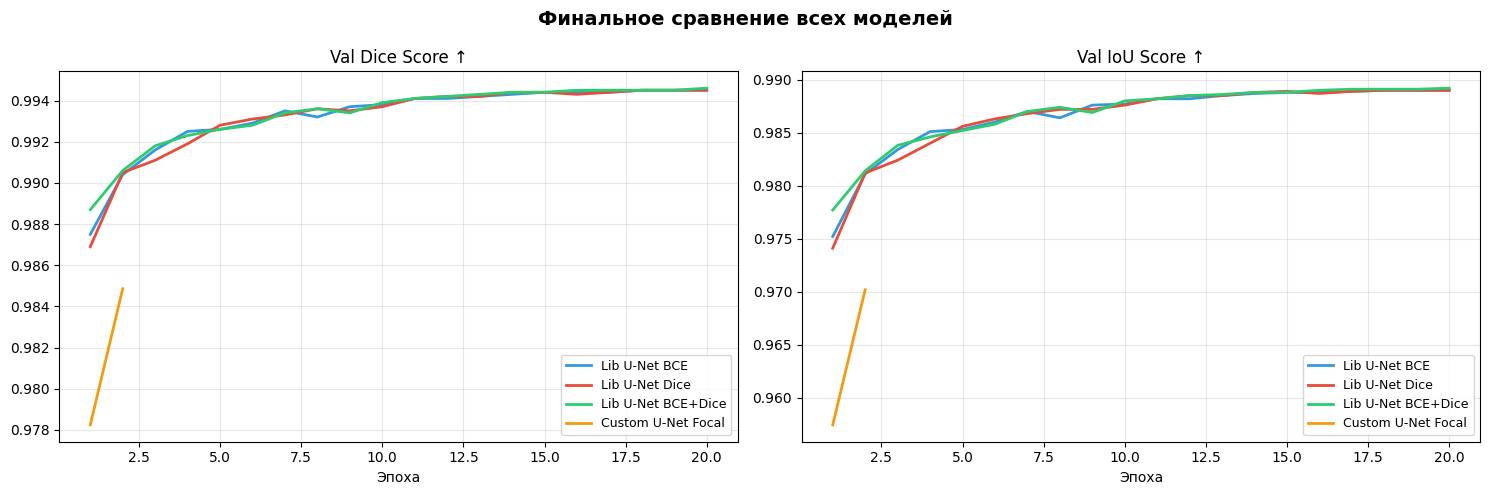


Модель                     |  Лучший Dice |  Лучший IoU
-------------------------------------------------------
Lib U-Net BCE              |       0.9945 |      0.9890
Lib U-Net Dice             |       0.9945 |      0.9890
Lib U-Net BCE+Dice         |       0.9946 |      0.9892
Custom U-Net Focal         |       0.9849 |      0.9702


In [22]:
# Финальное сравнение библиоточной и собственной моделей
all_history_candidates ={
"Lib U-Net BCE":globals ().get ("history_bce"),
"Lib U-Net Dice":globals ().get ("history_dice"),
"Lib U-Net BCE+Dice":globals ().get ("history_combo"),
"Custom U-Net Focal":globals ().get ("custom_history"),
}
all_histories ={k :v for k ,v in all_history_candidates .items () if v is not None }
if len (all_histories )==0 :
    raise RuntimeError (
    "Нет ни одной истории обучения для финального сравнения. Запустите ячейки обучения."
    )

fig ,axes =plt .subplots (1 ,2 ,figsize =(15 ,5 ))
fig .suptitle ("Финальное сравнение всех моделей",fontsize =14 ,fontweight ="bold")
colors =["#3498db","#e74c3c","#2ecc71","#f39c12"]

for (name ,h ),c in zip (all_histories .items (),colors ):
    ep =range (1 ,len (h ["val_dice"])+1 )
    axes [0 ].plot (ep ,h ["val_dice"],label =name ,color =c ,lw =2 )
    axes [1 ].plot (ep ,h ["val_iou"],label =name ,color =c ,lw =2 )

for ax ,title in zip (axes ,["Val Dice Score ↑","Val IoU Score ↑"]):
    ax .set_title (title ,fontsize =12 )
    ax .set_xlabel ("Эпоха")
    ax .legend (fontsize =9 )
    ax .grid (alpha =0.3 )

plt .tight_layout ()
plt .show ()

print (f"\n{'Модель':<26} | {'Лучший Dice':>12} | {'Лучший IoU':>11}")
print ("-"*55 )
for name ,h in all_histories .items ():
    print (f"{name :<26} | {max (h ['val_dice']):>12.4f} | {max (h ['val_iou']):>11.4f}")


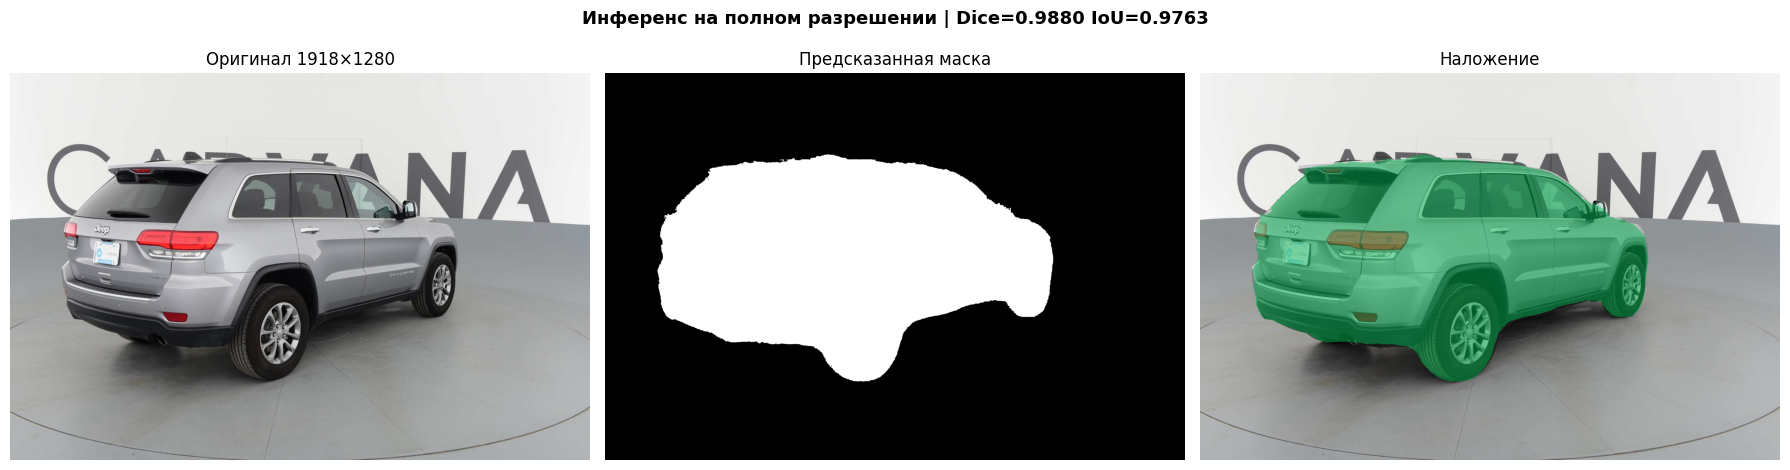

In [23]:
# Визуализация изображений, масок и наложения
def predict_full_resolution (model ,img_path ,mask_path =None ,
tile_size =None ):
    model .eval ()
    orig_img =Image .open (img_path ).convert ("RGB")
    orig_size =orig_img .size

    transform =val_transform
    img_t ,_ =val_dataset [0 ]
    aug =transform (image =np .array (orig_img ),mask =np .zeros ((*orig_img .size [::-1 ],),
    dtype =np .float32 ))
    img_t =aug ["image"].unsqueeze (0 ).to (DEVICE )

    with torch .no_grad ():
        pred =torch .sigmoid (model (img_t ))

    pred_full =nn .functional .interpolate (
    pred ,size =(orig_size [1 ],orig_size [0 ]),
    mode ="bilinear",align_corners =False
    )
    pred_mask =(pred_full .squeeze ().cpu ().numpy ()>0.5 ).astype (np .uint8 )

    fig ,axes =plt .subplots (1 ,3 ,figsize =(18 ,5 ))
    fig .suptitle ("Инференс на полном разрешении",fontsize =13 ,fontweight ="bold")

    orig_arr =np .array (orig_img )
    overlay =orig_arr .copy ()
    overlay [pred_mask ==1 ]=(overlay [pred_mask ==1 ]*0.5 +
    np .array ([0 ,180 ,80 ])*0.5 ).astype (np .uint8 )

    axes [0 ].imshow (orig_arr )
    axes [0 ].set_title (f"Оригинал {orig_size [0 ]}×{orig_size [1 ]}")
    axes [0 ].axis ("off")

    axes [1 ].imshow (pred_mask ,cmap ="gray")
    axes [1 ].set_title ("Предсказанная маска")
    axes [1 ].axis ("off")

    axes [2 ].imshow (overlay )
    axes [2 ].set_title ("Наложение")
    axes [2 ].axis ("off")

    if mask_path :
        gt =(np .array (Image .open (mask_path ).convert ("L"))>127 ).astype (np .uint8 )
        intersection =(pred_mask &gt ).sum ()
        union =(pred_mask |gt ).sum ()
        dice_val =2 *intersection /(pred_mask .sum ()+gt .sum ()+1e-8 )
        iou_val =intersection /(union +1e-8 )
        fig .suptitle (
        f"Инференс на полном разрешении | Dice={dice_val :.4f} IoU={iou_val :.4f}",
        fontsize =13 ,fontweight ="bold"
        )

    plt .tight_layout ()
    plt .show ()
    return pred_mask

custom_model .load_state_dict (
torch .load ("best_custom_unet.pth",map_location =DEVICE )
)
test_idx =random .randint (0 ,len (val_imgs )-1 )
_ =predict_full_resolution (custom_model ,val_imgs [test_idx ],val_masks [test_idx ])


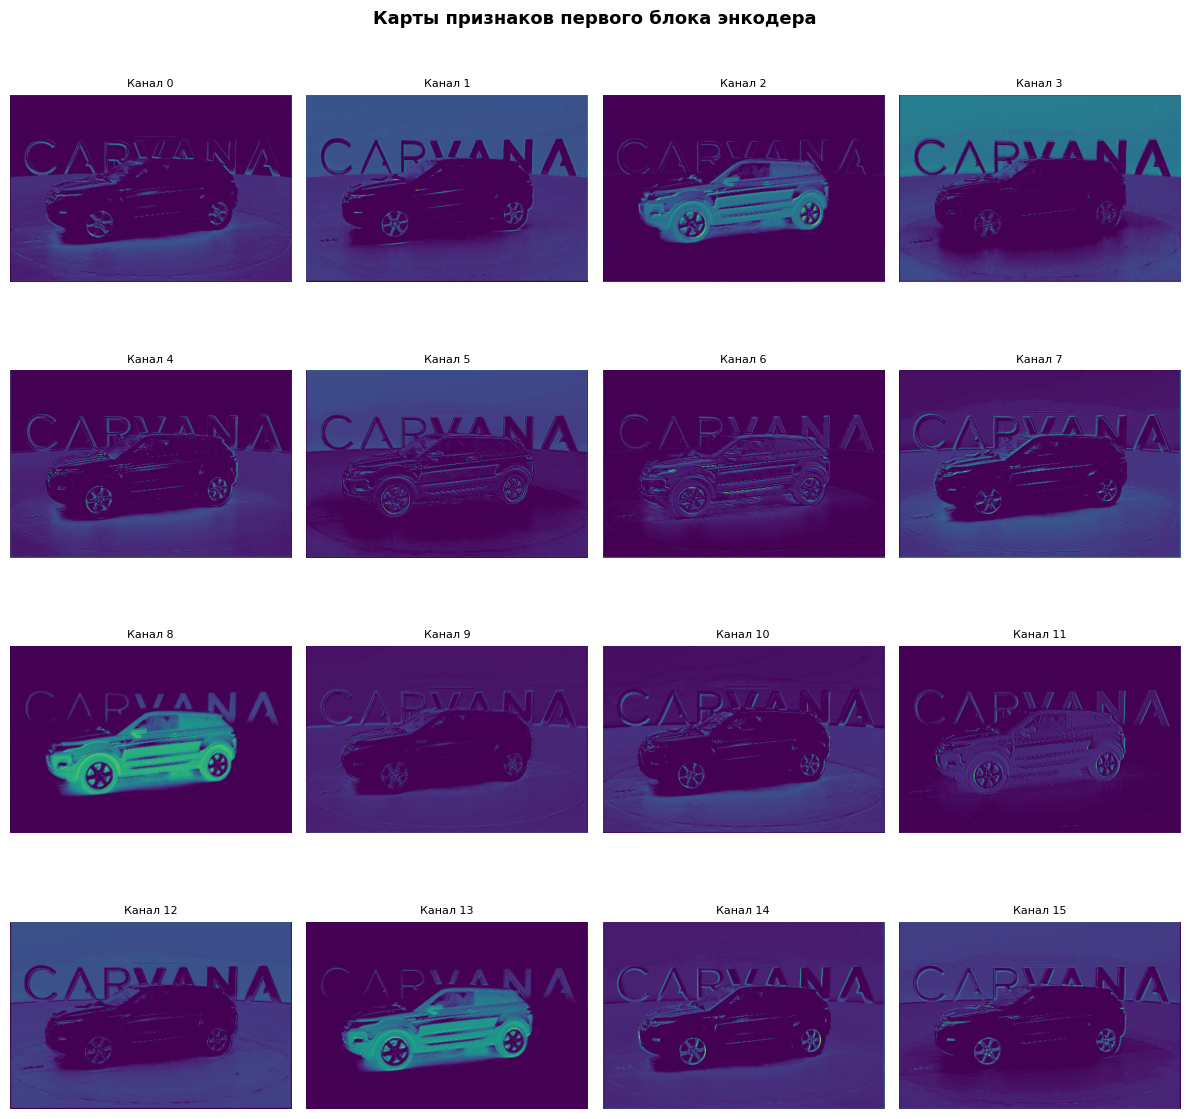

In [24]:
def visualize_feature_maps (model ,dataset ,idx =0 ,layer_name ="encoder_layer1"):
    activations ={}

    def hook_fn (module ,inp ,out ):
        activations ["feat"]=out .detach ().cpu ()

    hook =model .encoders [0 ].conv .register_forward_hook (hook_fn )

    model .eval ()
    img_t ,_ =dataset [idx ]
    with torch .no_grad ():
        model (img_t .unsqueeze (0 ).to (DEVICE ))

    hook .remove ()

    feats =activations ["feat"][0 ]
    n_show =min (16 ,feats .shape [0 ])

    fig ,axes =plt .subplots (4 ,4 ,figsize =(12 ,12 ))
    fig .suptitle ("Карты признаков первого блока энкодера",
    fontsize =13 ,fontweight ="bold")
    for i ,ax in enumerate (axes .flat ):
        if i <n_show :
            ax .imshow (feats [i ].numpy (),cmap ="viridis")
            ax .set_title (f"Канал {i }",fontsize =8 )
        ax .axis ("off")

    plt .tight_layout ()
    plt .show ()

visualize_feature_maps (custom_model ,val_dataset )
